<div align="center">

![Titanic Survival Prediction — project cover](../assets/project-banner.svg)

# Titanic Survival Prediction

**An end-to-end, notebook-first machine-learning case study**  
Exploratory Data Analysis · Feature Engineering · Classical ML · Hyperparameter Optimization

`Binary classification` &nbsp; · &nbsp; `Scikit-learn` &nbsp; · &nbsp; `Logistic Regression` &nbsp; · &nbsp; `GridSearchCV`

</div>

> **Notebook contract:** All executable Python cells are retained from the original project. This enhanced edition adds explanations and supporting repository documentation, but does not modify model code, inputs, parameters, or predictions. Existing machine-specific warning streams have been removed from saved output only.

## Research question

Can information recorded about a Titanic passenger—such as sex, passenger class, age, family relationships, ticket, and cabin—be used to predict the passenger's binary survival label?

**Target:** `Survived` (`0` = did not survive, `1` = survived). The label is supplied for the training set and deliberately absent from the competition test set.

## Notebook navigation

1. **Setup and data loading:** libraries and CSV inputs.
2. **Initial review:** schema, descriptive statistics, missingness, duplicates, and numeric outliers.
3. **Feature engineering:** titles, tickets, cabins, family indicators, missing-age flags, and a log-transformed fare.
4. **Missing-value treatment:** grouped imputation using title and passenger class.
5. **Training preparation:** stratified train/validation split and categorical/numeric transformations.
6. **Modeling:** algorithm screening with LazyPredict, followed by regularized logistic regression and 5-fold grid search.
7. **Evaluation and delivery:** validation predictions, error analysis, and a two-column competition submission.

**Verified saved result:** The selected logistic-regression pipeline achieves **184 correct predictions out of 223 validation passengers**, or **82.51% validation accuracy**, as recorded in the original notebook's confusion matrix. This is **not** a Kaggle leaderboard score. See [the final report](../docs/FINAL_REPORT.md) for the provenance of all reported metrics.

---

# 01 — Environment and Libraries

The project uses **pandas / NumPy** for data manipulation, **Matplotlib / Seaborn** for visualization, **scikit-learn** for preprocessing and modeling, **category_encoders** for categorical frequency encoding, and **LazyPredict** to compare baseline classification algorithms.

- Preprocessing is represented with reusable `Pipeline` and `ColumnTransformer` objects.
- Hyperparameters are selected with `GridSearchCV`.
- Predictions are assessed using a classification report and confusion matrix.

For a fresh environment, install the repository dependencies as described in [Reproducibility](../docs/REPRODUCIBILITY.md). The saved notebook metadata identifies Python **3.14.7** as the author's original execution environment; the complete package versions were not captured.

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import re
from category_encoders import CountEncoder
from sklearn.pipeline import make_pipeline,Pipeline
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder,StandardScaler
from sklearn.compose import ColumnTransformer
from lazypredict.Supervised import LazyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV
from sklearn.metrics import confusion_matrix,classification_report

# 02 — Load the Titanic Datasets

The two files serve different roles:

| Dataset | Rows | Columns | Target available? | Purpose |
|:--|--:|--:|:--:|:--|
| `train.csv` | 891 | 12 | Yes | Supervised learning and local validation |
| `test.csv` | 418 | 11 | No | Produce competition-format predictions |

The notebook's unchanged code uses Windows-style relative paths, `..\Data\train.csv` and `..\Data\test.csv`. **Run the notebook from the `Notebooks/` directory on Windows**, with `Data/` next to it. This path choice is intentionally preserved; the portability limitation is documented rather than silently patched.

The provided CSV files are preserved in the repository. Their schema and row counts can be checked without training a model using `python scripts/validate_project.py`.

In [21]:
train_raw_df = pd.read_csv(r"..\Data\train.csv")
test_raw_df = pd.read_csv(r"..\Data\test.csv")

# 03 — Initial Dataset Review

Before fitting a model, inspect types, record counts, the numeric distribution, and the availability of labels. The data contains **891 labeled training observations** and **418 unlabeled test observations**.

Key characteristics of the supplied training data:

- **342 survived** (`38.38%`) and **549 did not survive** (`61.62%`); the classes are imbalanced, though both have substantial representation.
- Both datasets include demographic, ticketing, accommodation, and family-related fields.
- Numeric features are on different scales, making the later use of `StandardScaler` appropriate for regularized linear modeling.
- Missing values are concentrated in `Age` and `Cabin`, with a small number also present in `Embarked` (train) and `Fare` (test).

![Survival class distribution](../assets/survival-distribution.png)

*Descriptive counts above come directly from the included `Data/train.csv`; they are not model predictions.*

### 3.1 — Training Schema and Completeness

`DataFrame.info()` confirms the training row count, inferred dtypes, and non-null counts. This gives a first view of which columns will need imputation or transformation before modeling.

In [22]:
train_raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


### 3.2 — Numeric Descriptive Statistics

`describe()` summarizes the numeric features with counts, central tendency, spread, and quantiles. The original data includes a wide fare range and different magnitudes across predictors; inspect these distributions before applying scaling and logarithmic transformations.

In [23]:
train_raw_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### 3.3 — Unlabeled Test Schema

The competition test set lacks `Survived`, as expected. The **same feature-engineering procedure** will be applied to both datasets, but only the training set can support supervised metrics.

In [24]:
test_raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    str    
 3   Sex          418 non-null    str    
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    str    
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     str    
 10  Embarked     418 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 52.8 KB


# 04 — Data Quality and Preprocessing Review

This stage evaluates duplicate records, missing observations, and the spread of numerical features before constructing engineered predictors. The following checks are **diagnostic** rather than data-cleansing operations: the notebook does not automatically drop duplicates or remove outliers.

![Missingness by source dataset](../assets/missingness.png)

**Important distinction:** the raw `train.csv` and `test.csv` datasets are retained unchanged. All feature changes occur in new pandas DataFrames created in memory.

## 4.1 — Exact Duplicate Rows

`.duplicated().sum()` counts rows whose full set of column values repeats another row. This is not equivalent to detecting repeated `Name`, `Ticket`, or family membership; several passengers can legitimately share parts of their record.

**Observed result:** **0** fully duplicated rows in either training or test data. `PassengerId` is also unique within each included CSV. The notebook reports duplicates but does not delete rows.

In [25]:
print('train data:',train_raw_df.duplicated().sum())
print('test data:',test_raw_df.duplicated().sum())

train data: 0
test data: 0


## 4.2 — Missing-Value Audit

The training dataset contains the following null counts:

| Column | Missing / 891 | % missing | Planned handling in this notebook |
|---|---:|---:|---|
| `Age` | 177 | 19.87% | Median within `Title × Pclass` groups |
| `Cabin` | 687 | 77.10% | Convert into `CabinDeck` (`Unknown` if missing) and `CabinCount` |
| `Embarked` | 2 | 0.22% | Mode within `Title × Pclass` groups |

In `test.csv`, **86 ages**, **327 cabins**, and **1 fare** are missing. Missing `Fare` is handled **after** logarithmic transformation by a grouped mean imputer. `AgeMissing` explicitly retains an indicator of the original age missingness. No claim is made that these methods are optimal; they are the actual choices in the submitted code.

**Methodological caution:** grouped imputation is computed on each dataset **before** the later train/validation split. That means validation-set feature distributions contribute to training-side imputation statistics. No survival labels are used in these imputers, but a stricter validation design would fit all imputations using training-fold data only.

In [26]:
print(train_raw_df.isna().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


## 4.3 — Numeric Distributions and Outliers

The horizontal boxplots summarize the median, quartiles, and potential extreme values of all seven numeric training columns: `PassengerId`, `Survived`, `Pclass`, `Age`, `SibSp`, `Parch`, and `Fare`.

- Values outside the boxplot whiskers are **visualization-based outlier candidates**, not necessarily erroneous observations.
- Large fares and family-member counts can represent legitimate passengers rather than bad data.
- The notebook uses logarithmic transformations for `Fare` and ticket numbers later, but **does not perform outlier deletion or winsorization**.

The original run emitted a Matplotlib warning concerning the deprecated `vert=False` argument. The Python code is retained as written, so the warning may reappear in environments with newer Matplotlib versions.

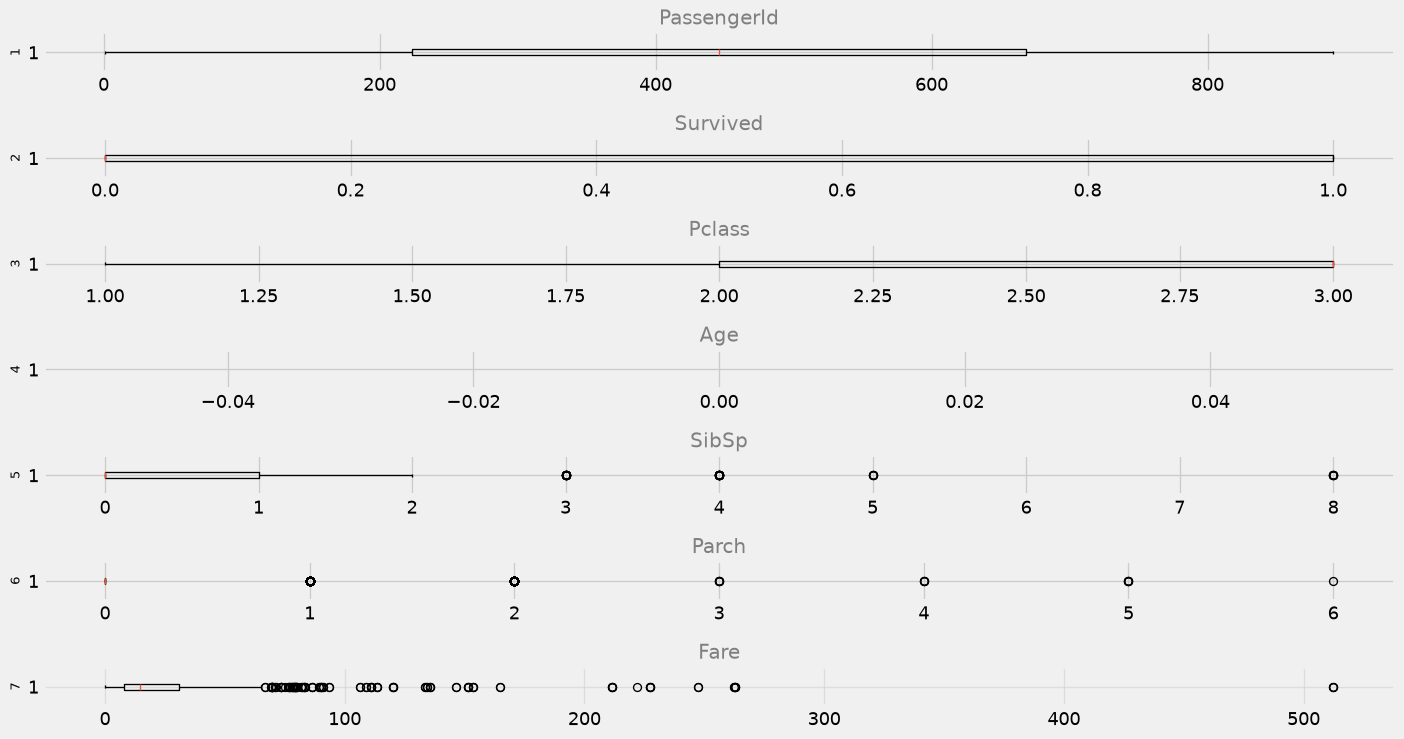

In [27]:
plt.style.use('fivethirtyeight')

fig,axs=plt.subplots(7,1,dpi=95,figsize=(15,8),sharex=False)
i=0
for col in train_raw_df.select_dtypes('number').columns:
    axs[i].boxplot(train_raw_df[col],vert=False)
    axs[i].set_title(col,size=15,color='gray')
    axs[i].set_ylabel(i+1,size=10)
    i+=1

plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

# 05 — Feature Engineering

Raw Titanic fields contain useful structure that is not directly accessible to a simple linear classifier. The `feature_engineering(data_frame)` function returns a **copy** of its input with new predictive fields and some original text columns removed.

| Source | Engineered features | Transformation and intuition |
|---|---|---|
| `Name` | `Title` | Map honorifics into `Mr`, `Mrs`, `Miss`, `Master`, and `Rare` |
| `Ticket` | `TicketPrefix`, `TicketNumber`, `TicketLength` | Normalize prefix, parse numeric suffix, take `log(number + 1)`, retain raw length |
| `Cabin` | `CabinDeck`, `CabinCount` | Retain first deck letter and count cabin tokens; missing cabins become `Unknown`, `0` |
| `SibSp`, `Parch` | `FamilySize`, `IsAlone` | `FamilySize = SibSp + Parch + 1`; `IsAlone = 1` when both counts are zero |
| `Age` | `AgeMissing` | Indicator equal to `1` if original age is missing |
| `Fare` | `FareLog` | `ln(Fare + 1)`, with the source fare column removed |

After deriving these features, the function drops `Name`, `Ticket`, `Cabin`, `SibSp`, `Parch`, and `Fare`. It preserves `PassengerId`, target labels when present, and other input columns.

### Implementation notes

- The parser relies on the formats observed in the included Titanic records; unusual ticket strings could require additional defensive handling in future work.
- `TicketNumber` receives a log transform after parsing, and missing cabin information is represented by explicit sentinel features.
- Features are created on train and test **separately** using the same function.
- The implementation iterates over rows. A vectorized implementation would be faster, but is outside the scope of this code-preserving edition.

In [28]:
def feature_engineering(data_frame):

    #----------------------------------------------------------------
    # Title
    #----------------------------------------------------------------

    data_frame=data_frame.copy()
    data_frame['Title']=pd.NA
    
    for Index1 in range(data_frame.shape[0]):
        passenger_name=data_frame['Name'].iloc[Index1]
        if (passenger_name.find('Mr.') != -1):
            data_frame.loc[Index1, 'Title'] = "Mr"
        elif (passenger_name.find('Mrs.') != -1) or (passenger_name.find('Mme.') != -1):
            data_frame.loc[Index1, 'Title'] = "Mrs"
        elif (passenger_name.find('Miss.') != -1) or (passenger_name.find('Ms.') != -1) or (passenger_name.find('Mlle.') != -1):
            data_frame.loc[Index1, 'Title'] = "Miss"
        elif (passenger_name.find('Master.') != -1):
            data_frame.loc[Index1, 'Title'] = "Master"
        else:
            data_frame.loc[Index1, 'Title'] = "Rare"

    data_frame = data_frame.drop(columns=["Name"])

    #----------------------------------------------------------------
    # Ticket (Prefix - Number - Length - Frequency)
    #----------------------------------------------------------------

    data_frame['TicketPrefix']=pd.NA
    data_frame['TicketNumber']=0
    data_frame['TicketLength']=0
    # data_frame['TicketFrequency']=pd.NA

    for Index1 in range(data_frame.shape[0]):
        passenger_ticket=(data_frame['Ticket'].iloc[Index1]).upper()

        # TicketPrefix & TicketNumber
        if len(passenger_ticket.split(' ')) >= 2:

            ticket_prefix=''
            for Tick_num in passenger_ticket.split(' ')[:-1]:
                ticket_prefix = ticket_prefix + Tick_num
            ticket_prefix=ticket_prefix.replace('/','')
            ticket_prefix=ticket_prefix.replace('.','')
            data_frame.loc[Index1,'TicketPrefix']=ticket_prefix

            ticket_number=passenger_ticket.split(' ')[-1]
            ticket_number=ticket_number.replace('/','')
            ticket_number=ticket_number.replace('.','')
            data_frame.loc[Index1,'TicketNumber']=int(ticket_number)

        elif len(passenger_ticket.split(' ')) == 1:

            if re.search('[A-Z]+',passenger_ticket):
                ticket_prefix=passenger_ticket
                ticket_prefix=ticket_prefix.replace('/','')
                ticket_prefix=ticket_prefix.replace('.','')
                data_frame.loc[Index1,'TicketPrefix']=ticket_prefix

                data_frame.loc[Index1,'TicketNumber']=0

            elif re.search('[0-9]+',passenger_ticket):
                data_frame.loc[Index1,'TicketPrefix']='NONE'
                ticket_number=passenger_ticket
                ticket_number=ticket_number.replace('/','')
                ticket_number=ticket_number.replace('.','')
                data_frame.loc[Index1,'TicketNumber']=int(ticket_number)

        # TicketLength
        data_frame.loc[Index1,'TicketLength']=len(passenger_ticket)

        # # TicketFrequency
        # ticket_frequency=0
        # for tick_freq in (data_frame['Ticket']):
        #     if passenger_ticket.lower() == tick_freq.lower(): ticket_frequency+=1
        # data_frame.loc[Index1,'TicketFrequency']=ticket_frequency

    data_frame['TicketNumber']=np.log(data_frame['TicketNumber']+1)
    
    data_frame = data_frame.drop(columns=["Ticket"])

    #----------------------------------------------------------------
    #  Cabin (Deck - Count)
    #----------------------------------------------------------------

    data_frame['CabinDeck']=pd.NA
    data_frame['CabinCount']=0

    for Index1 in range(data_frame.shape[0]):
        passenger_cabin=(data_frame['Cabin'].iloc[Index1])
        if pd.isna(passenger_cabin) == False:
            passenger_cabin=passenger_cabin.upper()
            data_frame.loc[Index1,'CabinDeck']=passenger_cabin[0]
            data_frame.loc[Index1,'CabinCount']=len(passenger_cabin.split(' '))
        else:
            data_frame.loc[Index1,'CabinDeck']="Unknown"
            data_frame.loc[Index1,'CabinCount']=0

    data_frame = data_frame.drop(columns=["Cabin"])

    #----------------------------------------------------------------
    # FamilySize
    #----------------------------------------------------------------

    data_frame['FamilySize']=0
    data_frame['IsAlone']=0

    for Index1 in range(data_frame.shape[0]):
        passenger_SibSp=(data_frame['SibSp'].iloc[Index1])
        passenger_Parch=(data_frame['Parch'].iloc[Index1])

        data_frame.loc[Index1,'FamilySize']=passenger_SibSp+passenger_Parch+1

        if (passenger_SibSp+passenger_Parch) > 0:
            data_frame.loc[Index1,'IsAlone']=0
        else:
            data_frame.loc[Index1,'IsAlone']=1

    data_frame = data_frame.drop(columns=["SibSp"])
    data_frame = data_frame.drop(columns=["Parch"])

    #----------------------------------------------------------------
    # AgeMissing
    #----------------------------------------------------------------
    
    data_frame['AgeMissing']=0

    for Index1 in range(data_frame.shape[0]):
        passenger_Age=(data_frame['Age'].iloc[Index1])

        if pd.isna(passenger_Age) == False:        
            data_frame.loc[Index1,'AgeMissing']=0
        else:
            data_frame.loc[Index1,'AgeMissing']=1

    #----------------------------------------------------------------
    # FareLog
    #----------------------------------------------------------------
    
    data_frame['FareLog']=np.log(data_frame['Fare']+1)
    data_frame = data_frame.drop(columns=["Fare"])

    return data_frame

### 5.1 — Apply the Same Feature-Engineering Function to Both Data Sources

The function is invoked separately on the train and test DataFrames. It returns engineered copies, avoiding direct mutation of the raw loaded objects.

In [29]:
train_df=feature_engineering(train_raw_df)
test_df=feature_engineering(test_raw_df)

# 06 — Missing-Value Imputation

Three helper functions fill missing values by the combination of **passenger title (`Title`) and ticket class (`Pclass`)**, rather than by a single unconditional average for the entire dataset.

| Variable | Aggregation | Why it is used here |
|---|---|---|
| `Age` | Group **median** | Robust central tendency for a numeric feature |
| `Embarked` | Group **mode** | Most frequent category in the group |
| `FareLog` | Group **mean** | Numeric group-level replacement after logarithmic scaling |

For every helper, `data_frame.copy()` ensures a new frame is returned. The notebook uses the same functions for training and competition-test data, each with its own grouped statistics. One consequence is that **the fitted imputation statistics are not shared between train and test**.

> **Validation caveat:** imputation happens before the split, rather than inside a fitted pipeline. The final evaluation should therefore be interpreted as a saved experiment, not as a leakage-proof performance estimate.

## 6.1 — Grouped Median Imputer

For each `Title × Pclass` group, missing values are replaced with the group's **median**. The function is used for `Age` and is compatible with the numeric distribution's long tails.

**Formula:** for group \(g\) and missing observation \(i\), \(x_i \leftarrow \operatorname{median}(x_j : j \in g, x_j\text{ observed})\).

The implementation has **no fallback** for groups in which every value is missing; such groups can remain incomplete. This behavior is preserved from the source notebook.

In [30]:
def median_group_imputer(data_frame,column_name):
    data_frame=data_frame.copy()
    data_frame[column_name] = data_frame.groupby(['Title', 'Pclass'])[column_name].transform(
        lambda x: x.fillna(x.median())
    )

    return data_frame

## 6.2 — Grouped Mean Imputer

The `mean_group_imputer` fills missing numeric values with the mean calculated within the same `(Title, Pclass)` group.

Here it is applied to `FareLog` rather than the original fare amount, so the replacement is performed on the logarithmic scale. This is useful for documentation when interpreting the model coefficient or a future inverse transform; **it is not the same as taking the log of the group's original-fare mean**.

In [31]:
def mean_group_imputer(data_frame,column_name):
    data_frame=data_frame.copy()
    data_frame[column_name] = data_frame.groupby(['Title', 'Pclass'])[column_name].transform(
        lambda x: x.fillna(x.mean())
    )

    return data_frame

## 6.3 — Grouped Mode Imputer

For a categorical feature, the **mode** is the most frequently occurring observed category within a group. The code computes `x.mode()[0]` and uses that category for missing values.

It is applied to `Embarked`. A group with **no observed category** would cause a failure because the mode series would be empty; no fallback is implemented in the original Python code.

In [32]:
def mode_group_imputer(data_frame,column_name):
    data_frame=data_frame.copy()
    data_frame[column_name] = data_frame.groupby(['Title', 'Pclass'])[column_name].transform(
        lambda x: x.fillna(x.mode()[0])
    )

    return data_frame

## 6.4 — Impute `Age`

The notebook first prints training-group age medians and then fills missing ages in both datasets. These examples are taken from the saved output:

| Title | Class | Training median age |
|---|---:|---:|
| `Master` | 1 | 4 |
| `Miss` | 1 | 30 |
| `Mr` | 1 | 40 |
| `Mr` | 3 | 26 |
| `Mrs` | 2 | 32 |

The use of title recognizes that a passenger's name encodes information related to age, while class captures a different source of passenger heterogeneity. `AgeMissing` remains available as a separate feature so the fact that age was absent is not discarded.

In [33]:
print(train_df.groupby(['Title','Pclass'])['Age'].median())

Title   Pclass
Master  1          4.0
        2          1.0
        3          4.0
Miss    1         30.0
        2         24.0
        3         18.0
Mr      1         40.0
        2         31.0
        3         26.0
Mrs     1         40.0
        2         32.0
        3         31.0
Rare    1         48.5
        2         46.5
Name: Age, dtype: float64


In [34]:
train_df=median_group_imputer(train_df,'Age')
test_df=median_group_imputer(test_df,'Age')

## 6.5 — Impute `Embarked`

`Embarked` refers to the boarding port (`C`, `Q`, or `S`). The training-group mode is printed for inspection before missing values are replaced.

In the saved training output, **most groups have `S` as their mode**, with `Miss` in first class showing `C`. The actual replacements for the training and competition test sets are computed independently; no shared statistics are fitted.

In [35]:
print(train_df.groupby(['Title','Pclass'])['Embarked'].agg(lambda x: x.mode()[0]))

Title   Pclass
Master  1         S
        2         S
        3         S
Miss    1         C
        2         S
        3         S
Mr      1         S
        2         S
        3         S
Mrs     1         S
        2         S
        3         S
Rare    1         S
        2         S
Name: Embarked, dtype: str


In [36]:
train_df=mode_group_imputer(train_df,'Embarked')
test_df=mode_group_imputer(test_df,'Embarked')

## 6.6 — Impute `FareLog`

The engineered fare is `FareLog = ln(Fare + 1)`. The original test set has **one missing fare**, which becomes a missing `FareLog`; this step replaces it using the mean within title and class.

The notebook prints grouped training means to make the magnitude of those values auditable. These are logged amounts rather than ticket prices in raw currency units.

In [37]:
print(train_df.groupby(['Title','Pclass'])['FareLog'].mean())

Title   Pclass
Master  1         4.746805
        2         3.295287
        3         3.262730
Miss    1         4.591026
        2         2.938072
        3         2.600975
Mr      1         3.804556
        2         2.725433
        3         2.338365
Mrs     1         4.418785
        2         3.127053
        3         2.868869
Rare    1         3.560582
        2         2.805846
Name: FareLog, dtype: float64


In [38]:
train_df=mean_group_imputer(train_df,'FareLog')
test_df=mean_group_imputer(test_df,'FareLog')

# 07 — Feature / Target Separation and Validation Split

`Survived` is removed from the predictors and becomes `y_train`. `PassengerId` is excluded from modeling but retained in the competition test frame so prediction rows can be joined to the expected submission identifier.

The labeled data is divided into a stratified training/validation split:

| Setting | Value |
|---|---|
| `test_size` | `0.25` |
| `random_state` | `42` |
| `stratify` | `y_train` |
| Shuffling | `True` |
| Resulting fitting subset | **668 passengers** |
| Resulting validation subset | **223 passengers** |

Stratification helps maintain a similar proportion of survived/not-survived observations in each partition. The external **418-row `test.csv` is never a validation set** because it does not include the true survival target.

**Scope note:** the current order is feature engineering + imputation, followed by splitting. For stricter out-of-sample validation, transformation and learned imputation should be fitted on the 668-row training partition alone. The notebook code remains unchanged.

### 7.1 — Build the Matrix and Stratified Holdout

The code constructs feature matrices with the target and identifier excluded, then performs a reproducible train/validation split (`random_state=42`). Treat `X_test` as a prediction-only dataset rather than an evaluation set.

In [39]:
X_train=train_df.drop(columns=['PassengerId','Survived'])
y_train=train_df['Survived']

X_test=test_df.drop(columns=['PassengerId'])

X_train,X_val,y_train,y_val=train_test_split(X_train,y_train,test_size=0.25,random_state=42,stratify=y_train,shuffle=True)

# 08 — Encoding and Scaling

The model receives a mixture of original and engineered features. `ColumnTransformer` applies separate preprocessing techniques by column type, then concatenates the resulting features.

![Preprocessing and modeling overview](../assets/pipeline-overview.svg)

| Transformer | Input columns | Behavior |
|---|---|---|
| `OrdinalEncoder` | `Sex` | Encodes a known binary categorical predictor as a number |
| `OneHotEncoder(handle_unknown='ignore')` | `Embarked`, `Title`, `CabinDeck` | Creates indicator columns and tolerates unseen categories in later transforms |
| `StandardScaler` | `Age`, `TicketLength`, `TicketNumber`, `CabinCount`, `FamilySize`, `FareLog`, `Pclass` | Centers and scales numeric predictors |
| `CountEncoder` followed by `StandardScaler` | `TicketPrefix` | Uses category frequencies, then standardizes them |
| `remainder='passthrough'` | Columns not listed above | Leaves remaining engineered fields, such as `IsAlone` and `AgeMissing`, available to the model |

The manually transformed matrices are used to screen candidate algorithms with LazyPredict. The final logistic-regression model instead includes preprocessing **inside its own pipeline**. This is an important separation between algorithm screening and the final fitted estimator.

In [40]:
ordinal_encode=OrdinalEncoder()
one_hot_encoder=OneHotEncoder(handle_unknown='ignore')
standard_scaler=StandardScaler()

In [41]:
count_encoder_pipline=make_pipeline(
    CountEncoder(),
    StandardScaler()
)

### 8.1 — The `ColumnTransformer` Contract

Each input feature has one designated transformation branch; columns not explicitly assigned are passed through. Fitting this object learns vocabulary, category frequencies, and scaling statistics from the fitting portion of the data.

In [42]:
all_transformation=ColumnTransformer([
    ('OE',ordinal_encode,['Sex']),
    ('OHE',one_hot_encoder,['Embarked','Title','CabinDeck']),
    ('SS',standard_scaler,['Age','TicketLength','TicketNumber','CabinCount','FamilySize','FareLog','Pclass']),
    ('CEP',count_encoder_pipline,['TicketPrefix'])
],remainder='passthrough')

### 8.2 — Fit Transformations on the Training Subset

Only `X_train` is used to call `.fit_transform()`. The named output columns and source indices are retained in the resulting DataFrame, which assists model-screening diagnostics.

In [43]:
X_train_transformed=all_transformation.fit_transform(X_train)
X_train_transformed=pd.DataFrame(X_train_transformed,columns=all_transformation.get_feature_names_out(),index=X_train.index)

### 8.3 — Transform Validation Data Without Refitting

The existing fitted transformer is applied to `X_val` via `.transform()`. This prevents validation data from controlling its own one-hot vocabulary or scaling statistics during this transformation stage.

In [44]:
X_val_transformed=all_transformation.transform(X_val)
X_val_transformed=pd.DataFrame(X_val_transformed,columns=all_transformation.get_feature_names_out(),index=X_val.index)

### 8.4 — Transform Competition Test Data Without Refitting

The test predictors are transformed using the **same** transformer fitted on the labeled training subset. `OneHotEncoder(handle_unknown='ignore')` protects against unseen one-hot categories.

In [45]:
X_test_transformed=all_transformation.transform(X_test)
X_test_transformed=pd.DataFrame(X_test_transformed,columns=all_transformation.get_feature_names_out(),index=X_test.index)

# 09 — Model Development

This notebook compares several classification algorithms using the same stratified validation split and then investigates a regularized logistic-regression classifier more deeply.

- **Screening stage:** `LazyClassifier` fits many estimators and reports validation metrics.
- **Chosen modeling family:** `LogisticRegression`, whose preprocessing is packaged in a `Pipeline`.
- **Optimization stage:** `GridSearchCV` performs five-fold cross-validated tuning of solver, regularization strength, regularization type, and class weighting.
- **Final stage:** the selected estimator generates validation predictions and a competition test-set submission.

A model's performance on a validation set that has already been used to compare methods may be optimistic. The reported figures are useful for this project, but they should not be presented as a completely independent final test estimate.

## 9.1 — Baseline Algorithm Screening with LazyPredict

`LazyClassifier` is instantiated with `random_state=42`, `n_jobs=-1`, and `classifiers='all'`. Despite the `cv=5` constructor argument, the visible call supplies a designated training set and validation set; the saved table reports scores from those supplied data partitions.

**Top entries in the saved model table** (rounded to four decimal places):

| Estimator | Accuracy | Balanced accuracy | ROC AUC | F1 |
|---|---:|---:|---:|---:|
| `LinearSVC` | 0.8341 | 0.8260 | 0.8609 | 0.8343 |
| `CalibratedClassifierCV` | 0.8296 | 0.8180 | 0.8613 | 0.8292 |
| `LinearDiscriminantAnalysis` | 0.8251 | 0.8144 | 0.8626 | 0.8249 |
| `RidgeClassifier` | 0.8251 | 0.8144 | 0.8625 | 0.8249 |
| `LogisticRegression` | 0.8161 | 0.8114 | 0.8606 | 0.8170 |

**Interpretation:** LinearSVC has the highest listed validation accuracy in this excerpt, but the subsequent experiment deliberately explores logistic regression as the final model family. The final tuned logistic-regression accuracy must not be misrepresented as the best score across all screened models.

In [46]:
lazy_classifier=LazyClassifier(ignore_warnings=True,random_state=42,n_jobs=-1,cv=5,classifiers='all',use_gpu=False)

In [47]:
models,prediction=lazy_classifier.fit(X_train_transformed,X_val_transformed,y_train,y_val)

### 9.1.1 — Inspect the Top Ten Screened Models

The next cell displays the first ten rows of the LazyPredict results. The ranking is a guide for choosing a modeling family; it is not a nested-cross-validation comparison or a held-out final test.

In [48]:
models[:10]

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Accuracy CV Mean,Accuracy CV Std,Balanced Accuracy CV Mean,Balanced Accuracy CV Std,ROC AUC CV Mean,ROC AUC CV Std,F1 Score CV Mean,F1 Score CV Std,Precision CV Mean,Precision CV Std,Recall CV Mean,Recall CV Std,Time Taken
Model,,,,,,,,,,,,,,,,,,,
LinearSVC,0.834081,0.826006,0.860932,0.834256,0.834467,0.834081,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.832073
CalibratedClassifierCV,0.829596,0.818027,0.861271,0.829211,0.828965,0.829596,0.821906,0.034909,0.803093,0.036874,0.869071,0.028746,0.820096,0.035220,0.820732,0.035875,0.821906,0.034909,0.244782
LinearDiscriminantAnalysis,0.825112,0.814378,0.862629,0.824919,0.824760,0.825112,0.814409,0.027035,0.798545,0.025907,0.870919,0.027305,0.813332,0.026572,0.813983,0.027443,0.814409,0.027035,3.513270
RidgeClassifier,0.825112,0.814378,0.862545,0.824919,0.824760,0.825112,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.925560
RidgeClassifierCV,0.825112,0.814378,0.862205,0.824919,0.824760,0.825112,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.493657
LogisticRegression,0.816143,0.811407,0.860592,0.817032,0.818753,0.816143,0.812928,0.039264,0.795087,0.040560,0.871149,0.028331,0.811423,0.039349,0.811763,0.040130,0.812928,0.039264,3.219260
AdaBoostClassifier,0.807175,0.806272,0.846249,0.808694,0.812860,0.807175,0.829346,0.034796,0.820981,0.036644,0.886977,0.025076,0.829542,0.034724,0.830354,0.034857,0.829346,0.034796,3.469190
LGBMClassifier,0.807175,0.795451,0.849644,0.806962,0.806782,0.807175,0.820290,0.032462,0.804710,0.033756,0.876097,0.034565,0.819145,0.032755,0.819908,0.033291,0.820290,0.032462,3.161387
NuSVC,0.789238,0.787345,0.853548,0.790899,0.795142,0.789238,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.392898


## 9.2 — Logistic Regression Pipeline

The baseline logistic-regression pipeline combines **the same `all_transformation` preprocessing object** with a logistic model configured with `random_state=42`, `max_iter=5000`, and an initial `class_weight='balanced'` setting.

For binary classification, logistic regression models the probability of class 1 as:

\[ P(Y=1\mid X)=\frac{1}{1+e^{-(\beta_0+\beta^\top X)}}. \]

It is a relatively interpretable linear classifier. Regularization penalizes model complexity and can help generalization in the presence of multiple one-hot and engineered features. The code later tunes the class weighting and penalty strength rather than keeping the baseline settings fixed.

In [49]:
LR_pipeline=make_pipeline(
    all_transformation,
    LogisticRegression(random_state=42,n_jobs=-1,verbose=2,max_iter=5000,class_weight='balanced')
)

### 9.2.1 — Fit the Initial Pipeline

Calling `.fit(X_train, y_train)` trains the transformer and logistic-regression estimator on the **668-row fitting partition**. In the final pipeline, transformations are fitted during the pipeline's own `.fit()`, helping the downstream estimator receive consistently encoded features.

The original saved output includes a warning that `n_jobs` has no effect on `LogisticRegression` in newer scikit-learn versions. Because the code-preservation requirement takes precedence, this option has not been changed; a warning may appear when rerun.

In [50]:
LR_pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['Pclass','Sex','Age',...,'IsAlone','AgeMissing','FareLog']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('OE', ...), ('OHE', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthroug

### 9.2.2 — Hyperparameter Search

The grid evaluates several regularization choices:

| Family | `l1_ratio` | Solver choices | Candidate combinations |
|---|---:|---|---:|
| L1 (lasso-like) | `1` | `liblinear`, `saga` | 24 |
| L2 (ridge-like) | `0` | `lbfgs`, `liblinear`, `saga` | 36 |
| Elastic net | `0.1` to `0.9` | `saga` | 72 |
| **Total** | | | **132** |

The search also varies inverse regularization strength `C` and `class_weight` (`None` or `'balanced'`). The metric for model selection is **weighted F1**, calculated in **5-fold cross-validation** on the fitting partition.

**Experiment size:** `132 candidates × 5 folds = 660 fits` (as confirmed in the saved output). The grid is computationally expensive; this repository does not make CI rerun it. Note that larger `C` means *weaker* regularization in scikit-learn's logistic regression.

In [51]:
param_grid = [
    # Lasso (L1): l1_ratio=1
    {
        'logisticregression__l1_ratio': [1],
        'logisticregression__solver': ['liblinear', 'saga'],
        'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'logisticregression__class_weight': [None, 'balanced']
    },
    
    # Ridge (L2): l1_ratio=0
    {
        'logisticregression__l1_ratio': [0],
        'logisticregression__solver': ['lbfgs', 'liblinear', 'saga'],
        'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'logisticregression__class_weight': [None, 'balanced']
    },
    
    #  Elasticnet: l1_ratio between 0 & 1
    {
        'logisticregression__l1_ratio': np.linspace(0.1, 0.9, 9),  # 9 مقدار بین 0.1 تا 0.9
        'logisticregression__solver': ['saga'],
        'logisticregression__C': [0.01, 0.1, 1, 10],
        'logisticregression__class_weight': [None, 'balanced']
    }
]

### 9.2.2.1 — Define the Cross-Validation Search

`scoring='f1_weighted'` weights class-wise F1 by class support. The folds are internal to `GridSearchCV`; the separate validation set is reserved for the subsequent evaluation, although it has already been viewed during algorithm screening.

In [52]:
GS_CV=GridSearchCV(LR_pipeline,param_grid,cv=5,scoring='f1_weighted',n_jobs=-1,verbose=2)

### 9.2.2.2 — Execute the 660-Fit Search

The saved run shows five folds over 132 candidates. The runtime depends on available cores, installed package versions, and solver convergence. The repository's automatic checks intentionally validate the artifacts without retraining the entire search.

In [53]:
GS_CV.fit(X_train,y_train)

Fitting 5 folds for each of 132 candidates, totalling 660 fits


convergence after 345 epochs took 0 seconds


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... verbose=2))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'logisticregression__C': [0.001, 0.01, ...], 'logisticregression__class_weight': [None, 'balanced'], 'logisticregression__l1_ratio': [1], 'logisticregression__solver': ['liblinear', 'saga']}, {'logisticregression__C': [0.001, 0.01, ...], 'logisticregression__class_weight': [None, 'balanced'], 'logisticregression__l1_ratio': [0], 'logisticregression__solver': ['lbfgs', 'liblinear', ...]}, ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_weighted'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric e

### 9.2.2.3 — Best Hyperparameters

Inspect the exact parameter combination returned by cross-validation, rather than copying the initial logistic-regression configuration. Here the selected model uses L1 regularization and does not use the initial balanced class weighting.

In [54]:
GS_CV.best_params_

{'logisticregression__C': 1,
 'logisticregression__class_weight': None,
 'logisticregression__l1_ratio': 1,
 'logisticregression__solver': 'saga'}

### 9.2.2.4 — Best Mean Cross-Validation Score

This value is the mean **weighted F1 across training-partition folds**, not accuracy and not a Kaggle test-set score. The saved result is approximately **0.8219**.

In [55]:
GS_CV.best_score_

np.float64(0.8218763593070856)

### 9.2.3 — Select the Best Tuned Estimator

The best recorded cross-validation weighted-F1 score is **0.8218763593**. The selected settings are:

```text
logisticregression__C:            1
logisticregression__class_weight: None
logisticregression__l1_ratio:      1
logisticregression__solver:        saga
```

`GS_CV.best_estimator_` is an already-fitted preprocessing-and-model pipeline. The notebook then uses it directly for validation predictions; it does **not** show a separate refit on all 891 labeled passengers before generating the competition submission.

In [56]:
LR_BestModel=GS_CV.best_estimator_

### 9.3 — Predict on the Validation Set

Use the tuned pipeline's `.predict()` method on `X_val` to obtain discrete binary labels for the 223 passengers in the validation partition.

In [57]:
y_pred1=LR_BestModel.predict(X_val)

### 9.4 — Classification Report

The saved report summarizes **precision**, **recall**, **F1**, and **support** per class. The surviving class (`1`) has lower precision than class `0`, meaning positive survival predictions are less reliable than negative predictions in this evaluation.

| Metric | Class `0` | Class `1` |
|---|---:|---:|
| Precision (saved, rounded) | 0.87 | 0.76 |
| Recall (saved, rounded) | 0.85 | 0.79 |
| F1 (saved, rounded) | 0.86 | 0.78 |
| Support | 137 | 86 |

**Overall validation accuracy:** `184 / 223 = 0.825112…` (**82.51%**).

In [58]:
print(classification_report(y_val,y_pred1))

              precision    recall  f1-score   support

           0       0.87      0.85      0.86       137
           1       0.76      0.79      0.78        86

    accuracy                           0.83       223
   macro avg       0.81      0.82      0.82       223
weighted avg       0.83      0.83      0.83       223



### 9.5 — Confusion Matrix and Error Analysis

![Validation confusion matrix](../assets/validation-confusion-matrix.png)

The saved matrix is `[[116, 21], [18, 68]]`, with **rows = actual classes** and **columns = predicted classes**:

- **116** true negatives (class `0` correctly predicted).
- **21** false positives (predicted survival, actually `0`).
- **18** false negatives (predicted non-survival, actually `1`).
- **68** true positives (class `1` correctly predicted).

There are **39 misclassifications** out of 223 holdout passengers. This matrix supports the computed accuracy and positive-class precision/recall reported in the final report.

In [59]:
print(confusion_matrix(y_val,y_pred1))

[[116  21]
 [ 18  68]]


# 10 — Generate the Titanic Competition Submission

The selected fitted pipeline predicts `Survived` for each row in the **418-row unlabeled test dataset**. Predictions are combined with the test passengers' `PassengerId` values to produce the required two-column CSV:

| Column | Type | Meaning |
|---|---|---|
| `PassengerId` | Integer | Test passenger identifier, in original row order |
| `Survived` | `0` or `1` | Binary class prediction generated by the trained pipeline |

The notebook saves to **`Notebooks/submission.csv`**, relative to its working directory. The original submission snapshot is included separately at [`outputs/submission.csv`](../outputs/submission.csv) so the repository can keep generated working files out of version control.

**Saved submission counts:** **418** predictions, **243** zeros and **175** ones. These are predictions, **not confirmed Titanic survival outcomes**. A Kaggle competition/public leaderboard score was not included in the user-provided source material, so no such score is claimed here.

### 10.1 — Inference on the Competition Test Split

Only the predictor columns are passed to the fitted model. Since there are no test labels in the input files, prediction quality on these 418 rows cannot be measured locally.

In [60]:
y_pred2=LR_BestModel.predict(X_test)

### 10.2 — Preserve Passenger Identifiers

The competition format requires one prediction for each input passenger and must preserve the exact `PassengerId` mapping. This code uses the engineered test DataFrame's identifier column, then attaches the binary predictions.

In [61]:
submission=pd.DataFrame(test_df['PassengerId'])
submission['Survived']=y_pred2

### 10.3 — Export the CSV

`index=False` prevents pandas from adding an unwanted unnamed CSV index. The repository's lightweight verification script checks the saved submission for the expected two columns, 418 rows, binary outputs, and correspondence with the provided test IDs.

---

## Further Reading and Reproducibility

- [Final project report](../docs/FINAL_REPORT.md) — objectives, methods, saved results, and limitations.
- [Model card](../docs/MODEL_CARD.md) — intended use, evaluation, and limitations.
- [Data dictionary](../docs/DATA_DICTIONARY.md) — original columns and engineered fields.
- [Run instructions](../docs/REPRODUCIBILITY.md) — setup and platform constraints.
- [Integrity manifest](../notebook-code-manifest.json) — hash checks proving the 43 Python source cells were preserved.

*All performance claims in this notebook are sourced from its original stored outputs or derived arithmetically from those outputs. The enriched notebook was not re-trained as part of the documentation process.*

In [62]:
submission.to_csv("submission.csv",index=False)